# Project 09 — Logistics Delivery ETA Prediction & Operational Intelligence

**Starter notebook · Phase 1.** Dataset is synthetic. Notebook sections are planned checkpoints, **not 20 development phases**. Results must come from executed analysis, never from illustrative examples.


## Run first — Phase 1 environment and dataset inspection

The dataset is already in `data/deliveries.csv`. Run the two cells below with the selected project `.venv` kernel.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "deliveries.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "deliveries.csv"
assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

print("Python:", sys.version.split()[0])
print("Dataset:", DATA_PATH)


Python: 3.13.16
Dataset: c:\Users\dell\Projects\logistics-delivery-eta-prediction\data\deliveries.csv


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["dispatch_datetime"])
print("Shape:", df.shape)
print("Date range:", df["dispatch_datetime"].min(), "→", df["dispatch_datetime"].max())
print("Target:", "actual_delivery_minutes")
print("Unique shipments:", df["shipment_id"].nunique())
display(df.head(5))


Shape: (10000, 16)
Date range: 2025-11-01 00:02:00 → 2026-10-31 23:56:00
Target: actual_delivery_minutes
Unique shipments: 10000


,shipment_id,dispatch_datetime,dispatch_hour,day_of_week,distance_km,origin_region,destination_region,vehicle_type,courier_service,package_weight_kg,delivery_priority,planned_stops,forecast_traffic_level,forecast_weather_condition,promised_delivery_minutes,actual_delivery_minutes
0,SH-008126,2025-11-01 00:02:00,0,5,11.81,South,East,Bike,In-House,0.94,Standard,1,Moderate,Cloudy,60,36.3
1,SH-005469,2025-11-01 00:34:00,0,5,27.10,North,East,Bike,In-House,1.32,Standard,2,Moderate,Clear,95,91.3
2,SH-006675,2025-11-01 02:54:00,2,5,19.02,West,East,Bike,Partner-A,1.12,Express,4,Moderate,Cloudy,80,76.9
3,SH-002222,2025-11-01 06:15:00,6,5,6.61,East,East,Bike,Partner-A,1.36,Standard,4,Low,Cloudy,70,58.8
4,SH-009748,2025-11-01 06:25:00,6,5,12.18,South,South,Bike,Partner-A,1.37,Standard,2,Low,Fog,90,44.7


## 01. Business Problem

Define dispatch-time duration prediction and why ETA is a continuous regression target. Management decision: review potentially late shipments.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


## 02. Dataset Understanding

Document grain, data dictionary, synthetic assumptions and valid dispatch-time features.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


## 03. Data Quality

Phase 2: run comprehensive one-pass QA, remediate only verified problems, validate and freeze the analysis dataset.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [3]:
import numpy as np
import pandas as pd
from IPython.display import display

target = "actual_delivery_minutes"
promise = "promised_delivery_minutes"

numeric_features = [
    "dispatch_hour",
    "day_of_week",
    "distance_km",
    "package_weight_kg",
    "planned_stops",
]

regions = {"North", "South", "East", "West", "Central"}
allowed_categories = {
    "origin_region": regions,
    "destination_region": regions,
    "vehicle_type": {"Bike", "Van", "Truck"},
    "courier_service": {"In-House", "Partner-A", "Partner-B"},
    "delivery_priority": {"Standard", "Express"},
    "forecast_traffic_level": {"Low", "Moderate", "High", "Severe"},
    "forecast_weather_condition": {"Clear", "Cloudy", "Rain", "Fog", "Storm"},
}

feature_cols = numeric_features + list(allowed_categories)
excluded_cols = {"shipment_id", "dispatch_datetime", promise, target}

raw = pd.read_csv(DATA_PATH)
expected_cols = set(feature_cols) | excluded_cols
assert set(raw.columns) == expected_cols, "Unexpected CSV columns."

checked = raw.copy()
trimmed_cells = 0

for col in ["shipment_id", "dispatch_datetime", *allowed_categories]:
    original = checked[col].astype("string")
    trimmed = original.str.strip()
    trimmed_cells += int(original.ne(trimmed).sum())
    checked[col] = trimmed.replace("", pd.NA)

duplicates_removed = int(checked.duplicated().sum())
checked = checked.drop_duplicates().copy()

checked["dispatch_datetime"] = pd.to_datetime(
    checked["dispatch_datetime"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

numeric_cols = numeric_features + [promise, target]
checked[numeric_cols] = checked[numeric_cols].apply(pd.to_numeric, errors="coerce")

dispatch = checked["dispatch_datetime"]
valid_dispatch = dispatch.between("2025-11-01", "2026-11-01", inclusive="left")
valid_id = checked["shipment_id"].str.fullmatch(r"SH-\d{6}", na=False)
valid_promise = checked[promise].ge(15) & checked[promise].mod(5).eq(0)
stops = checked["planned_stops"]
valid_stops = stops.between(1, 9) & stops.mod(1).eq(0)

checks = {
    "Missing or unparseable cells": checked.isna().sum().sum(),
    "Repeated shipment IDs": checked["shipment_id"].duplicated().sum(),
    "Malformed shipment IDs": (~valid_id).sum(),
    "Invalid dispatch dates": (~valid_dispatch).sum(),
    "Infinite numeric values": np.isinf(checked[numeric_cols]).sum().sum(),
    "Nonpositive actual duration": checked[target].le(0).sum(),
    "Invalid promised duration": (~valid_promise).sum(),
    "Distance outside 2 to 85 km": (~checked["distance_km"].between(2, 85)).sum(),
    "Weight outside 0.08 to 28 kg": (~checked["package_weight_kg"].between(0.08, 28)).sum(),
    "Invalid planned stops": (~valid_stops).sum(),
    "Dispatch hour mismatch": (~checked["dispatch_hour"].eq(dispatch.dt.hour)).sum(),
    "Dispatch weekday mismatch": (~checked["day_of_week"].eq(dispatch.dt.day_of_week)).sum(),
    "Excluded columns in model features": len(set(feature_cols) & excluded_cols),
}

for col, allowed in allowed_categories.items():
    checks[f"Invalid categories in {col}"] = (~checked[col].isin(allowed)).sum()

audit = pd.Series(checks, name="issues").rename_axis("check").to_frame()
audit["status"] = np.where(audit["issues"].eq(0), "PASS", "FAIL")
display(audit)

assert audit["issues"].eq(0).all(), "See the failed checks in the audit table."

q1, q3 = checked[target].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
long_deliveries = int(checked[target].gt(upper_fence).sum())

deliveries_clean = checked.sort_values(
    ["dispatch_datetime", "shipment_id"]
).reset_index(drop=True)

passed = int(audit["status"].eq("PASS").sum())
print(f"Checks passed: {passed}/{len(audit)}")
print(f"Whitespace corrections: {trimmed_cells} | Exact duplicate rows removed: {duplicates_removed}")
print(f"Upper-tail durations flagged: {long_deliveries} above {upper_fence:.1f} minutes")
print(f"Validated data: {deliveries_clean.shape} | Model inputs: {len(feature_cols)}")

,issues,status
check,,
Missing or unparseable cells,0,PASS
Repeated shipment IDs,0,PASS
Malformed shipment IDs,0,PASS
Invalid dispatch dates,0,PASS
Infinite numeric values,0,PASS
Nonpositive actual duration,0,PASS
Invalid promised duration,0,PASS
Distance outside 2 to 85 km,0,PASS
Weight outside 0.08 to 28 kg,0,PASS


Checks passed: 20/20
Whitespace corrections: 0 | Exact duplicate rows removed: 0
Upper-tail durations flagged: 216 above 214.4 minutes
Validated data: (10000, 16) | Model inputs: 12


## 04. Exploratory Data Analysis

Phase 2: quantitative KPIs and charts for duration, traffic, distance, dispatch hour, region and late-delivery rate.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


Total shipments: 10,000
Shipments in EDA: 6,000 | Dispatches before 2026-06-06 09:14:00
Mean / median duration: 97.15 / 88.00 min
Late shipments: 867/6,000 (14.45%)


shipments  mean_minutes  median_minutes  \
segment            group                                                
Distance (km)      Under 15        1053         48.31           47.20   
                   15 to <30       2082         75.11           73.40   
                   30 to <45       1536        108.98          106.75   
                   45 to <60        785        138.68          135.70   
                   60+              544        182.72          174.40   
Destination region Central         1052        102.96           92.85   
                   East            1235         98.34           90.80   
                   North           1238         95.38           85.55   
                   South           1191         93.96           84.10   
                   West            1284         95.91           87.40   
Vehicle            Bike            1469         71.24           62.40   
                   Truck           1430        126.91          121.90   
                   Van             3101         95.70           88.00   
Dispatch hour      00-05           1480         93.85           84.65   
                   06-11           1509         97.84           88.70   
                   12-17           1530         95.95           86.95   
                   18-23           1481        100.99           91.50   
Forecast traffic   Low             1304         83.75           77.90   
                   Moderate        2222         91.98           84.65   
                   High            1741        103.53           95.30   
                   Severe           733        121.55          111.30   

                              late_shipments  late_rate_pct  
segment            group                                     
Distance (km)      Under 15               80           7.60  
                   15 to <30             228          10.95  
                   30 to <45             275          17.90  
                   45 to <60             153          19.49  
                   60+                   131          24.08  
Destination region Central               214          20.34  
                   East                  194          15.71  
                   North                 160          12.92  
                   South                 143          12.01  
                   West                  156          12.15  
Vehicle            Bike                  169          11.50  
                   Truck                 254          17.76  
                   Van                   444          14.32  
Dispatch hour      00-05                 186          12.57  
                   06-11                 232          15.37  
                   12-17                 205          13.40  
                   18-23                 244          16.48  
Forecast traffic   Low                   102           7.82  
                   Moderate              245          11.03  
                   High                  295          16.94  
                   Severe                225          30.70

,Pearson r with duration
distance_km,0.866
planned_stops,0.306
package_weight_kg,0.163
dispatch_hour,0.042
day_of_week,-0.018


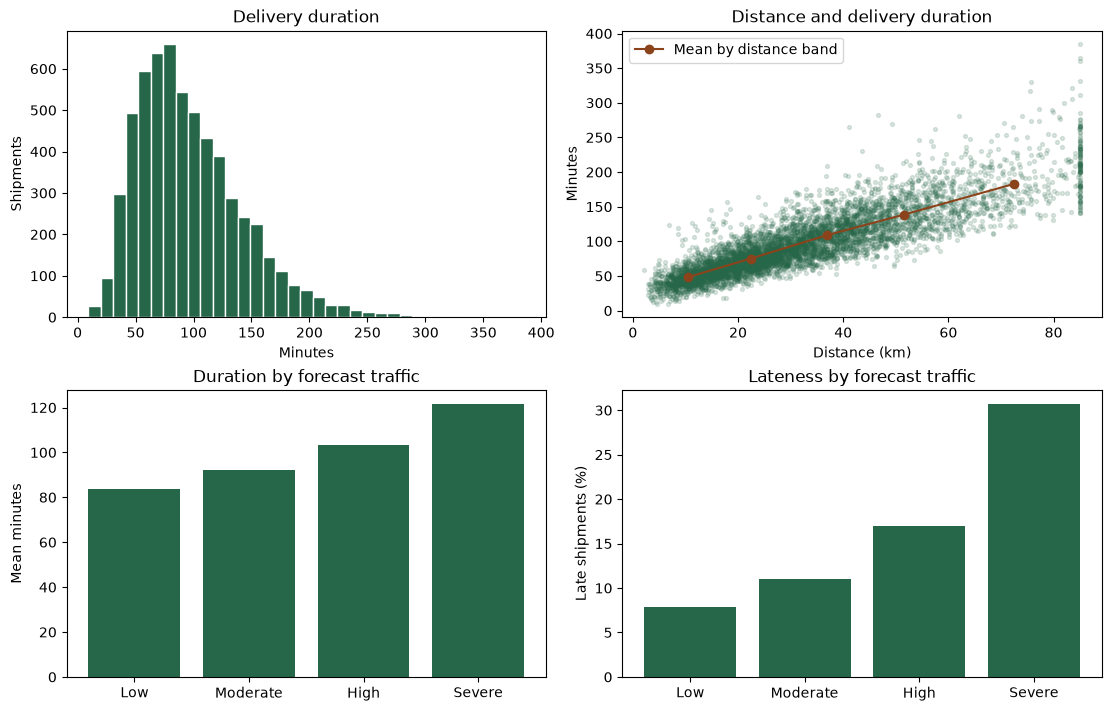

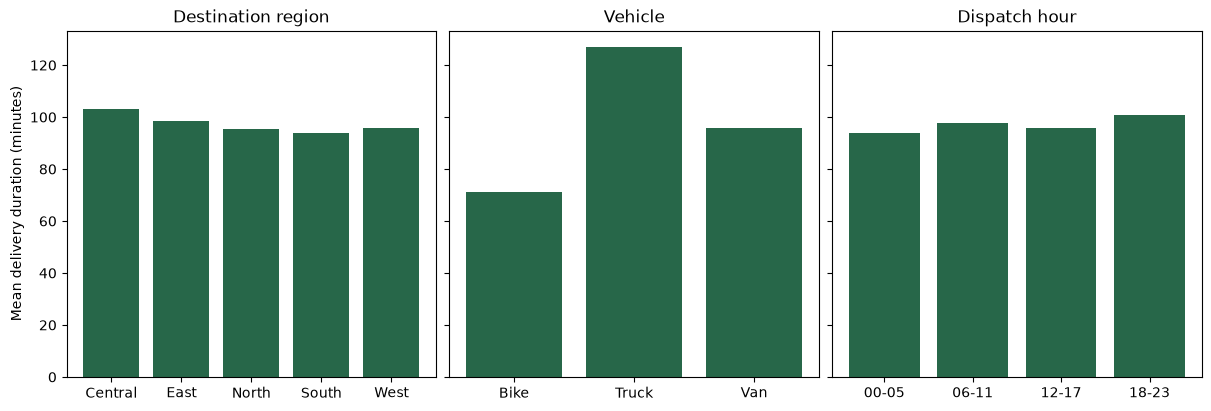

In [4]:
import matplotlib.pyplot as plt

dispatch_times = deliveries_clean["dispatch_datetime"]
train_cutoff = dispatch_times.iloc[int(len(deliveries_clean) * 0.60)]
eda = deliveries_clean.loc[dispatch_times < train_cutoff].copy()
eda["late"] = eda[target].gt(eda[promise])

eda["distance_band"] = pd.cut(
    eda["distance_km"],
    bins=[0, 15, 30, 45, 60, np.inf],
    labels=["Under 15", "15 to <30", "30 to <45", "45 to <60", "60+"],
    right=False,
)
eda["dispatch_period"] = pd.cut(
    eda["dispatch_hour"],
    bins=[0, 6, 12, 18, 24],
    labels=["00-05", "06-11", "12-17", "18-23"],
    right=False,
)
eda["forecast_traffic_level"] = pd.Categorical(
    eda["forecast_traffic_level"],
    categories=["Low", "Moderate", "High", "Severe"],
    ordered=True,
)

print(f"Total shipments: {len(deliveries_clean):,}")
print(f"Shipments in EDA: {len(eda):,} | Dispatches before {train_cutoff}")
print(f"Mean / median duration: {eda[target].mean():.2f} / {eda[target].median():.2f} min")
print(f"Late shipments: {eda['late'].sum():,}/{len(eda):,} ({eda['late'].mean():.2%})")

segment_columns = {
    "Distance (km)": "distance_band",
    "Destination region": "destination_region",
    "Vehicle": "vehicle_type",
    "Dispatch hour": "dispatch_period",
    "Forecast traffic": "forecast_traffic_level",
}
segment_tables = {}

for label, col in segment_columns.items():
    summary = eda.groupby(col, observed=True).agg(
        shipments=(target, "size"),
        mean_minutes=(target, "mean"),
        median_minutes=(target, "median"),
        late_shipments=("late", "sum"),
    )
    summary["late_rate_pct"] = 100 * summary["late_shipments"] / summary["shipments"]
    segment_tables[label] = summary

display(pd.concat(segment_tables, names=["segment", "group"]).round(2))

correlation = eda[numeric_features + [target]].corr()[target].drop(target)
display(correlation.sort_values(ascending=False).round(3).to_frame("Pearson r with duration"))

figures = DATA_PATH.parent.parent / "output" / "figures"
figures.mkdir(parents=True, exist_ok=True)
green = "#276749"

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")

axes[0, 0].hist(eda[target], bins=35, color=green, edgecolor="white")
axes[0, 0].set(title="Delivery duration", xlabel="Minutes", ylabel="Shipments")

axes[0, 1].scatter(eda["distance_km"], eda[target], s=8, alpha=0.16, color=green)
distance_means = eda.groupby("distance_band", observed=True)[["distance_km", target]].mean()
axes[0, 1].plot(
    distance_means["distance_km"], distance_means[target],
    "o-", color="#8b431b", label="Mean by distance band",
)
axes[0, 1].set(title="Distance and delivery duration", xlabel="Distance (km)", ylabel="Minutes")
axes[0, 1].legend()

traffic = segment_tables["Forecast traffic"]
axes[1, 0].bar(traffic.index, traffic["mean_minutes"], color=green)
axes[1, 0].set(title="Duration by forecast traffic", ylabel="Mean minutes")
axes[1, 1].bar(traffic.index, traffic["late_rate_pct"], color=green)
axes[1, 1].set(title="Lateness by forecast traffic", ylabel="Late shipments (%)")

fig.savefig(figures / "01_duration_and_traffic.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")

for ax, label in zip(axes, ["Destination region", "Vehicle", "Dispatch hour"]):
    summary = segment_tables[label]
    ax.bar(summary.index, summary["mean_minutes"], color=green)
    ax.set_title(label)

axes[0].set_ylabel("Mean delivery duration (minutes)")
fig.savefig(figures / "02_duration_by_segment.png", dpi=150)
plt.show()

## 05. Features and Target

Phase 2: target = `actual_delivery_minutes`; exclude ID, datetime (direct), promise, and all post-dispatch outcomes from predictive features.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


## 06. Data Splitting

Phase 2: chronological ~60% training / 20% validation / 20% untouched testing, preserving the date ordering.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [5]:
dispatch = deliveries_clean["dispatch_datetime"]
train_cutoff = dispatch.iloc[int(len(dispatch) * 0.60)]
test_cutoff = dispatch.iloc[int(len(dispatch) * 0.80)]

train_window = deliveries_clean.loc[dispatch < train_cutoff]
val_window = deliveries_clean.loc[
    (dispatch >= train_cutoff) & (dispatch < test_cutoff)
]
test_df = deliveries_clean.loc[dispatch >= test_cutoff].copy()


def completed_by(window, cutoff):
    duration = pd.to_timedelta(window[target], unit="min")
    completed_at = window["dispatch_datetime"] + duration
    return window.loc[completed_at <= cutoff].copy()


train_df = completed_by(train_window, train_cutoff)
val_df = completed_by(val_window, test_cutoff)

X_train, y_train = train_df[feature_cols].copy(), train_df[target].copy()
X_val, y_val = val_df[feature_cols].copy(), val_df[target].copy()
X_test, y_test = test_df[feature_cols].copy(), test_df[target].copy()

assert len(train_window) + len(val_window) + len(test_df) == len(deliveries_clean)
assert train_df["dispatch_datetime"].max() < val_df["dispatch_datetime"].min()
assert val_df["dispatch_datetime"].max() < test_df["dispatch_datetime"].min()
assert set(X_train.columns).isdisjoint(excluded_cols)

print("Validation starts:", train_cutoff)
print("Test starts:", test_cutoff)

for name, window, X in [
    ("Train", train_window, X_train),
    ("Validation", val_window, X_val),
    ("Test", test_df, X_test),
]:
    print(f"{name}: {len(X):,} of {len(window):,} shipments | X shape: {X.shape}")

Validation starts: 2026-06-06 09:14:00
Test starts: 2026-08-17 12:46:00
Train: 6,000 of 6,000 shipments | X shape: (6000, 12)
Validation: 1,998 of 2,000 shipments | X shape: (1998, 12)
Test: 2,000 of 2,000 shipments | X shape: (2000, 12)


## 07. Preprocessing

Phase 2: train-fitted imputation, OneHotEncoder and optional StandardScaler inside ColumnTransformer/Pipeline.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [6]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_features = list(allowed_categories)


def make_preprocessor(drop_category=None):
    categorical_pipeline = Pipeline([
        ("fill_missing", SimpleImputer(strategy="most_frequent", missing_values=pd.NA)),
        ("encode", OneHotEncoder(
            drop=drop_category,
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ])

    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ])


linear_preprocessor = make_preprocessor(drop_category="first")
tree_preprocessor = make_preprocessor()

for name, preprocessor in [
    ("Linear Regression", linear_preprocessor),
    ("Tree models", tree_preprocessor),
]:
    fitted = clone(preprocessor)
    train_ready = fitted.fit_transform(X_train)
    val_ready = fitted.transform(X_val)

    assert train_ready.shape[0] == len(X_train)
    assert val_ready.shape[0] == len(X_val)
    assert train_ready.shape[1] == val_ready.shape[1]
    assert np.isfinite(train_ready).all()
    assert np.isfinite(val_ready).all()

    print(f"{name}: train {train_ready.shape} | validation {val_ready.shape}")

Linear Regression: train (6000, 25) | validation (1998, 25)
Tree models: train (6000, 32) | validation (1998, 32)


## 08. Baseline Regression

Phase 3: explain and train `DummyRegressor(strategy="median")`; evaluate against validation data.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline_model = DummyRegressor(strategy="median")
baseline_model.fit(X_train, y_train)

baseline_val_pred = baseline_model.predict(X_val)
baseline_val_mae = mean_absolute_error(y_val, baseline_val_pred)
baseline_val_abs_error = (y_val - baseline_val_pred).abs()

print(f"Training median: {y_train.median():.2f} min")
print(
    f"Total absolute error: {baseline_val_abs_error.sum():,.2f} min "
    f"across {len(y_val):,} shipments"
)
print(f"Validation MAE: {baseline_val_mae:.2f} min")

Training median: 88.00 min
Total absolute error: 74,528.40 min across 1,998 shipments
Validation MAE: 37.30 min


## 09. Linear Regression

Phase 3: teach coefficients/intercept and OLS intuition, train model and interpret limitations.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [8]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from IPython.display import display

# Build preprocessing + regression pipeline
linear_pipeline = Pipeline([
    ("preprocessor", clone(linear_preprocessor)),
    ("model", LinearRegression())
])

# Learn relationships from training shipments
linear_pipeline.fit(X_train, y_train)

# Predict delivery duration for validation shipments
linear_val_pred = linear_pipeline.predict(X_val)

# Calculate validation error
linear_val_mae = mean_absolute_error(y_val, linear_val_pred)

# Compare with the baseline
mae_improvement = baseline_val_mae - linear_val_mae
improvement_pct = 100 * mae_improvement / baseline_val_mae

print(f"Baseline MAE: {baseline_val_mae:.2f} min")
print(f"Linear Regression MAE: {linear_val_mae:.2f} min")
print(f"MAE improvement: {mae_improvement:.2f} min")
print(f"Relative MAE reduction: {improvement_pct:.2f}%")

# Inspect two useful learned coefficients
encoded_names = (
    linear_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = pd.Series(
    linear_pipeline.named_steps["model"].coef_,
    index=encoded_names
)

print(f"\nIntercept: {linear_pipeline.named_steps['model'].intercept_:.2f}")
print(f"Distance coefficient: {coefficients['numeric__distance_km']:.2f}")
print(f"Planned stops coefficient: {coefficients['numeric__planned_stops']:.2f}")

# Show five historical validation predictions
prediction_comparison = pd.DataFrame({
    "shipment_id": val_df["shipment_id"].to_numpy(),
    "actual_minutes": y_val.to_numpy(),
    "predicted_minutes": linear_val_pred
})

prediction_comparison["error_minutes"] = (
    prediction_comparison["actual_minutes"]
    - prediction_comparison["predicted_minutes"]
)

display(prediction_comparison.head(5).round(2))

Baseline MAE: 37.30 min
Linear Regression MAE: 12.24 min
MAE improvement: 25.06 min
Relative MAE reduction: 67.18%

Intercept: 17.25
Distance coefficient: 2.15
Planned stops coefficient: 5.11


,shipment_id,actual_minutes,predicted_minutes,error_minutes
0,SH-007633,111.2,100.52,10.68
1,SH-002474,123.3,129.01,-5.71
2,SH-008669,109.6,101.89,7.71
3,SH-001875,52.9,85.90,-33.00
4,SH-001639,72.9,88.94,-16.04


## 10. Decision Tree Regression

Phase 3: explain leaf numerical predictions, split objective and regularization settings.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Build the Decision Tree regression pipeline
tree_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("model", DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Train the model
tree_pipeline.fit(X_train, y_train)

# Predict on training and validation sets
tree_train_pred = tree_pipeline.predict(X_train)
tree_val_pred = tree_pipeline.predict(X_val)

# Calculate MAE on both sets
tree_train_mae = mean_absolute_error(y_train, tree_train_pred)
tree_val_mae = mean_absolute_error(y_val, tree_val_pred)

# Compare all models evaluated so far
print(f"Baseline Validation MAE: {baseline_val_mae:.2f} min")
print(f"Linear Regression Validation MAE: {linear_val_mae:.2f} min")
print(f"Decision Tree Training MAE: {tree_train_mae:.2f} min")
print(f"Decision Tree Validation MAE: {tree_val_mae:.2f} min")

# Inspect tree complexity
tree_model = tree_pipeline.named_steps["model"]

print(f"Tree Depth: {tree_model.get_depth()}")
print(f"Number of Leaf Nodes: {tree_model.get_n_leaves()}")

# Check difference between training and validation errors
print(f"Train-Validation MAE Gap: {tree_val_mae - tree_train_mae:.2f} min")

Baseline Validation MAE: 37.30 min
Linear Regression Validation MAE: 12.24 min
Decision Tree Training MAE: 12.07 min
Decision Tree Validation MAE: 13.93 min
Tree Depth: 8
Number of Leaf Nodes: 128
Train-Validation MAE Gap: 1.86 min


## 11. Random Forest Regression

Phase 3: compare averaged regression-tree predictions; use bounded sensible parameter choices.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

# Step 1: Create the Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

# Step 2: Train on the training shipments
rf_pipeline.fit(X_train, y_train)

# Step 3: Predict training and validation durations
rf_train_pred = rf_pipeline.predict(X_train)
rf_val_pred = rf_pipeline.predict(X_val)

# Step 4: Calculate MAE
rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_val_mae = mean_absolute_error(y_val, rf_val_pred)

# Step 5: Compare models using the same validation set
print("=== VALIDATION MODEL COMPARISON ===")
print(f"Baseline MAE: {baseline_val_mae:.2f} min")
print(f"Linear Regression MAE: {linear_val_mae:.2f} min")
print(f"Decision Tree MAE: {tree_val_mae:.2f} min")
print(f"Random Forest MAE: {rf_val_mae:.2f} min")

print("\n=== RANDOM FOREST DIAGNOSTICS ===")
print(f"Training MAE: {rf_train_mae:.2f} min")
print(f"Validation MAE: {rf_val_mae:.2f} min")
print(f"Train-Validation Gap: {rf_val_mae - rf_train_mae:.2f} min")
print(f"Number of Trees: {rf_pipeline.named_steps['model'].n_estimators}")

print("\n=== BASELINE IMPROVEMENT ===")
print(f"MAE improvement: {baseline_val_mae - rf_val_mae:.2f} min")
print(f"Relative MAE reduction: {(baseline_val_mae - rf_val_mae) / baseline_val_mae * 100:.2f}%")

=== VALIDATION MODEL COMPARISON ===
Baseline MAE: 37.30 min
Linear Regression MAE: 12.24 min
Decision Tree MAE: 13.93 min
Random Forest MAE: 12.53 min

=== RANDOM FOREST DIAGNOSTICS ===
Training MAE: 9.27 min
Validation MAE: 12.53 min
Train-Validation Gap: 3.26 min
Number of Trees: 200

=== BASELINE IMPROVEMENT ===
MAE improvement: 24.77 min
Relative MAE reduction: 66.40%


## 12. LightGBM Regression

Phase 3: teach boosting, learning rate and leaves; train a real LGBMRegressor.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [11]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Step 1: Prepare the same 32 encoded features used by tree models.
# Retain column names when passing data to LightGBM.
lgbm_preprocessor = clone(tree_preprocessor)
lgbm_preprocessor.set_output(transform="pandas")

# Step 2: Build the LightGBM pipeline
lgbm_pipeline = Pipeline([
    ("preprocessor", lgbm_preprocessor),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=6,
        min_child_samples=20,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Step 3: Train the model
lgbm_pipeline.fit(X_train, y_train)

# Step 4: Predict durations
lgbm_train_pred = lgbm_pipeline.predict(X_train)
lgbm_val_pred = lgbm_pipeline.predict(X_val)

# Step 5: Evaluate training and validation errors
lgbm_train_mae = mean_absolute_error(y_train, lgbm_train_pred)
lgbm_val_mae = mean_absolute_error(y_val, lgbm_val_pred)

# Step 6: Compare all five models
comparison = pd.DataFrame({
    "Model": [
        "Median Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "LightGBM"
    ],
    "Validation_MAE": [
        baseline_val_mae,
        linear_val_mae,
        tree_val_mae,
        rf_val_mae,
        lgbm_val_mae
    ]
})

comparison = comparison.sort_values(
    "Validation_MAE"
).reset_index(drop=True)

print("=== FIVE MODEL VALIDATION COMPARISON ===")
display(comparison.round(2))

print("=== LIGHTGBM DIAGNOSTICS ===")
print(f"Training MAE: {lgbm_train_mae:.2f} min")
print(f"Validation MAE: {lgbm_val_mae:.2f} min")
print(
    f"Train-Validation Gap: "
    f"{lgbm_val_mae - lgbm_train_mae:.2f} min"
)

print("=== BASELINE IMPROVEMENT ===")
print(
    f"MAE Reduction: "
    f"{baseline_val_mae - lgbm_val_mae:.2f} min"
)
print(
    f"Relative Reduction: "
    f"{(baseline_val_mae - lgbm_val_mae) / baseline_val_mae * 100:.2f}%"
)

=== FIVE MODEL VALIDATION COMPARISON ===


,Model,Validation_MAE
0,LightGBM,11.38
1,Linear Regression,12.24
2,Random Forest,12.53
3,Decision Tree,13.93
4,Median Baseline,37.30


=== LIGHTGBM DIAGNOSTICS ===
Training MAE: 9.80 min
Validation MAE: 11.38 min
Train-Validation Gap: 1.58 min
=== BASELINE IMPROVEMENT ===
MAE Reduction: 25.92 min
Relative Reduction: 69.49%


## 13. Model Evaluation

Phase 3: teach, manually verify and calculate MAE, MSE, RMSE, R²; consider MAPE/adjusted R² only if appropriate.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [12]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Predictions already generated by our five models
model_predictions = {
    "Median Baseline": baseline_val_pred,
    "Linear Regression": linear_val_pred,
    "Decision Tree": tree_val_pred,
    "Random Forest": rf_val_pred,
    "LightGBM": lgbm_val_pred
}

# Evaluate all models using identical validation shipments
metrics_results = []

for model_name, predictions in model_predictions.items():

    mae = mean_absolute_error(y_val, predictions)
    mse = mean_squared_error(y_val, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, predictions)

    # MAPE is undefined for zero actual durations
    if (y_val > 0).all():
        mape = mean_absolute_percentage_error(
            y_val, predictions
        ) * 100
    else:
        mape = np.nan

    metrics_results.append({
        "Model": model_name,
        "MAE_min": mae,
        "MSE_min2": mse,
        "RMSE_min": rmse,
        "R2": r2,
        "MAPE_pct": mape
    })

# Complete model comparison
metrics_df = pd.DataFrame(metrics_results)

metrics_df = metrics_df.sort_values(
    "MAE_min", ascending=True
).reset_index(drop=True)

print("=== COMPLETE VALIDATION MODEL COMPARISON ===")
display(metrics_df.round(4))

# Additional Linear Regression diagnostic: adjusted R2
linear_train_pred = linear_pipeline.predict(X_train)

train_r2 = r2_score(y_train, linear_train_pred)

n = len(y_train)

p = len(
    linear_pipeline.named_steps[
        "preprocessor"
    ].get_feature_names_out()
)

adjusted_r2 = (
    1 - (1 - train_r2) * (n - 1) / (n - p - 1)
)

print("\n=== LINEAR REGRESSION TRAINING DIAGNOSTIC ===")
print(f"Training R2: {train_r2:.4f}")
print(f"Adjusted Training R2: {adjusted_r2:.4f}")
print(f"Number of Encoded Predictors: {p}")

# Inspect high-level findings without touching test data
best_validation_model = metrics_df.iloc[0]

print("\n=== VALIDATION LEADER ===")
print(f"Model: {best_validation_model['Model']}")
print(f"MAE: {best_validation_model['MAE_min']:.2f} min")
print(f"RMSE: {best_validation_model['RMSE_min']:.2f} min")
print(f"R2: {best_validation_model['R2']:.4f}")

=== COMPLETE VALIDATION MODEL COMPARISON ===


,Model,MAE_min,MSE_min2,RMSE_min,R2,MAPE_pct
0,LightGBM,11.3821,228.7206,15.1235,0.8979,13.0303
1,Linear Regression,12.2408,266.2390,16.3168,0.8812,14.1858
2,Random Forest,12.5322,280.0425,16.7345,0.8750,14.0689
3,Decision Tree,13.9340,342.1444,18.4971,0.8473,15.4595
4,Median Baseline,37.3015,2406.4440,49.0555,-0.0742,42.8958



=== LINEAR REGRESSION TRAINING DIAGNOSTIC ===
Training R2: 0.8728
Adjusted Training R2: 0.8723
Number of Encoded Predictors: 25

=== VALIDATION LEADER ===
Model: LightGBM
MAE: 11.38 min
RMSE: 15.12 min
R2: 0.8979


## 14. Model Comparison

Phase 3: validation-only model selection; comparison.csv includes median baseline and four ML models.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [15]:
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# =====================================================
# 1. CONFIRM SELECTED MODEL
# =====================================================

selected_model_name = "LightGBM"

assert metrics_df.iloc[0]["Model"] == selected_model_name
assert len(X_test) == 2000

print("=== FINAL MODEL SELECTION ===")
print("Selected model:", selected_model_name)
print(f"Validation MAE: {lgbm_val_mae:.2f} min")


# =====================================================
# 2. COMBINE TRAINING + VALIDATION DATA
# =====================================================

final_train_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
).sort_values(
    ["dispatch_datetime", "shipment_id"]
).reset_index(drop=True)

X_final_train = final_train_df[feature_cols].copy()
y_final_train = final_train_df[target].copy()

# Confirm all training outcomes were available
# before the test period started.
completion_times = (
    final_train_df["dispatch_datetime"]
    + pd.to_timedelta(y_final_train, unit="min")
)

assert completion_times.le(test_cutoff).all()

# Prevent target leakage
assert target not in X_final_train.columns
assert promise not in X_final_train.columns
assert len(X_final_train) == 7998

print("\n=== FINAL TRAINING DATA ===")
print(f"Training shipments: {len(X_final_train):,}")
print(f"Input features: {X_final_train.shape[1]}")
print(f"Test shipments: {len(X_test):,}")
print(f"Test cutoff: {test_cutoff}")


# =====================================================
# 3. FIT FINAL LIGHTGBM PIPELINE
# =====================================================

final_pipeline = clone(lgbm_pipeline)

final_pipeline.fit(
    X_final_train,
    y_final_train
)

print("\nFINAL LIGHTGBM TRAINING COMPLETE")


# =====================================================
# 4. EVALUATE ON UNTOUCHED TEST DATA
# =====================================================

final_test_pred = final_pipeline.predict(X_test)

assert np.isfinite(final_test_pred).all()
assert (final_test_pred > 0).all()

test_mae = mean_absolute_error(y_test, final_test_pred)
test_mse = mean_squared_error(y_test, final_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, final_test_pred)

test_mape = (
    mean_absolute_percentage_error(y_test, final_test_pred)
    * 100
)

test_signed_error = np.mean(
    y_test.to_numpy() - final_test_pred
)

print("\n=== FINAL TEST RESULTS ===")
print(f"Test shipments: {len(X_test):,}")
print(f"MAE: {test_mae:.2f} min")
print(f"MSE: {test_mse:.2f} min²")
print(f"RMSE: {test_rmse:.2f} min")
print(f"R2: {test_r2:.4f}")
print(f"MAPE: {test_mape:.2f}%")
print(f"Mean signed error: {test_signed_error:.2f} min")


# =====================================================
# 5. SAVE MODEL AND VALIDATION COMPARISON
# =====================================================

project_dir = DATA_PATH.parent.parent

models_dir = project_dir / "models"
output_dir = project_dir / "output"

models_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

model_path = (
    models_dir / "eta_regression_pipeline.joblib"
)

joblib.dump(final_pipeline, model_path)

metrics_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

model_metrics = {
    "selected_model": selected_model_name,
    "dataset_type": "synthetic",
    "final_training_shipments": len(X_final_train),
    "test_shipments": len(X_test),
    "test_start": str(test_cutoff),
    "validation_mae_before_refit": float(lgbm_val_mae),
    "final_test": {
        "mae_min": float(test_mae),
        "mse_min2": float(test_mse),
        "rmse_min": float(test_rmse),
        "r2": float(test_r2),
        "mape_pct": float(test_mape),
        "mean_signed_error_min": float(test_signed_error)
    }
}

with open(
    output_dir / "model_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(model_metrics, f, indent=4)


# =====================================================
# 6. RELOAD AND VERIFY MODEL
# =====================================================

reloaded_pipeline = joblib.load(model_path)

reloaded_predictions = reloaded_pipeline.predict(
    X_test.head(5)
)

np.testing.assert_allclose(
    reloaded_predictions,
    final_test_pred[:5],
    rtol=0,
    atol=1e-10
)

print("\n=== MODEL EXPORT VERIFICATION ===")
print(f"Saved model: {model_path.name}")
print("Reloaded model predictions: MATCH")
print("Validation comparison: SAVED")
print("Final test metrics: SAVED")
print("\nPHASE 3 FINAL EVALUATION COMPLETE")

=== FINAL MODEL SELECTION ===
Selected model: LightGBM
Validation MAE: 11.38 min

=== FINAL TRAINING DATA ===
Training shipments: 7,998
Input features: 12
Test shipments: 2,000
Test cutoff: 2026-08-17 12:46:00

FINAL LIGHTGBM TRAINING COMPLETE

=== FINAL TEST RESULTS ===
Test shipments: 2,000
MAE: 11.59 min
MSE: 242.01 min²
RMSE: 15.56 min
R2: 0.8889
MAPE: 13.39%
Mean signed error: 0.29 min

=== MODEL EXPORT VERIFICATION ===
Saved model: eta_regression_pipeline.joblib
Reloaded model predictions: MATCH
Validation comparison: SAVED
Final test metrics: SAVED

PHASE 3 FINAL EVALUATION COMPLETE


## 15. Residual Analysis

Phase 3: inspect actual-minus-predicted residual distributions, systematic underprediction and segment errors.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


=== LIGHTGBM RESIDUAL DIAGNOSTICS ===
Validation shipments: 1,998
Mean signed error: 0.83 min
Median signed error: -0.12 min
MAE: 11.38 min
RMSE: 15.12 min
90th percentile absolute error: 24.35 min
Predictions within +/-15 min: 72.67%
Underpredicted shipments: 989
Overpredicted shipments: 1,009
Underpredictions over 30 min: 75

=== ERROR BY DISTANCE BAND ===


,shipments,mean_error_min,mae_min,underprediction_rate_pct,rmse_min
distance_band,,,,,
60+,194,2.71,17.40,55.67,21.32
45 to <60,264,0.58,12.70,49.62,16.47
30 to <45,524,0.87,12.01,48.09,15.85
15 to <30,676,0.88,10.09,50.89,13.27
Under 15,340,-0.20,8.53,45.29,11.68



=== ERROR BY DESTINATION REGION ===


,shipments,mean_error_min,mae_min,underprediction_rate_pct,rmse_min
destination_region,,,,,
East,368,2.36,11.90,52.72,16.20
South,410,0.49,11.76,48.29,15.00
North,459,1.10,11.41,50.11,15.90
Central,321,1.46,11.01,52.96,14.75
West,440,-0.88,10.83,44.77,13.68



=== ERROR BY VEHICLE TYPE ===


,shipments,mean_error_min,mae_min,underprediction_rate_pct,rmse_min
vehicle_type,,,,,
Truck,485,1.83,13.12,51.96,17.34
Van,991,0.13,11.32,48.34,14.74
Bike,522,1.22,9.89,49.43,13.55


... (2 outputs left out)


=== ERROR BY DISPATCH PERIOD ===


,shipments,mean_error_min,mae_min,underprediction_rate_pct,rmse_min
dispatch_period,,,,,
18-23,521,0.94,11.75,49.90,14.90
12-17,475,0.42,11.68,47.58,15.56
06-11,526,0.75,11.10,48.48,15.27
00-05,476,1.21,10.99,52.10,14.76



=== FIVE LARGEST UNDERPREDICTIONS ===


,shipment_id,destination_region,distance_km,actual_minutes,predicted_minutes,residual_min
7946,SH-005326,North,12.96,135.6,44.76,90.84
7427,SH-006656,East,34.04,192.2,105.93,86.27
7364,SH-006429,North,43.30,194.3,118.24,76.06
7480,SH-005141,Central,85.00,275.0,211.08,63.92
7320,SH-002168,East,37.58,168.1,105.17,62.93


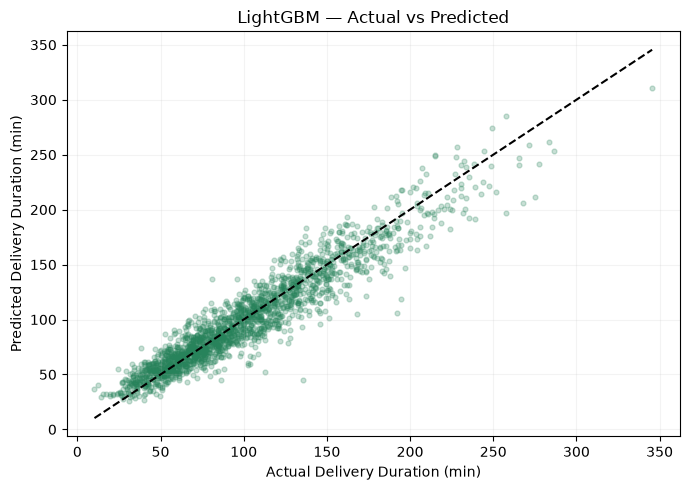

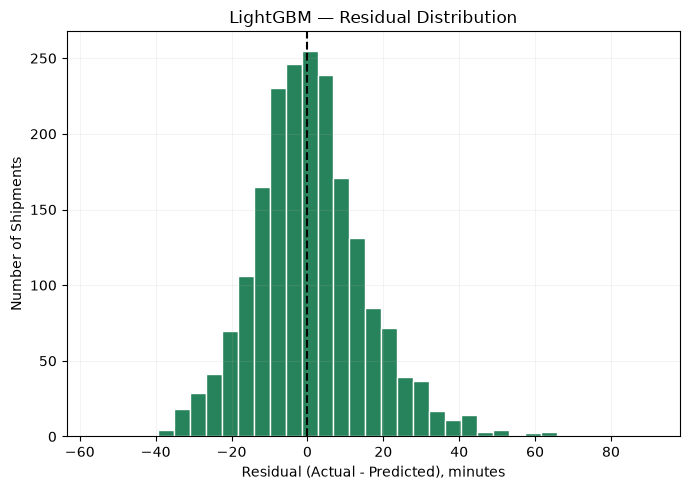

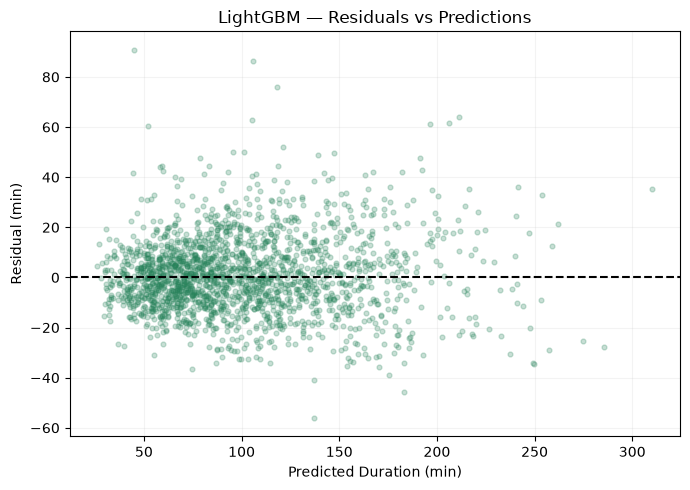


ALL THREE RESIDUAL FIGURES SAVED


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# =========================================================
# 1. CREATE THE VALIDATION RESIDUAL DATASET
# =========================================================

residual_df = val_df[
    [
        "shipment_id",
        "dispatch_datetime",
        "distance_km",
        "destination_region",
        "vehicle_type",
        "forecast_traffic_level",
        "promised_delivery_minutes"
    ]
].copy()

residual_df["actual_minutes"] = y_val.to_numpy()
residual_df["predicted_minutes"] = lgbm_val_pred

# Positive = underprediction; Negative = overprediction
residual_df["residual_min"] = (
    residual_df["actual_minutes"]
    - residual_df["predicted_minutes"]
)

residual_df["absolute_error_min"] = (
    residual_df["residual_min"].abs()
)

residual_df["squared_error_min2"] = (
    residual_df["residual_min"] ** 2
)

# =========================================================
# 2. OVERALL RESIDUAL DIAGNOSTICS
# =========================================================

n = len(residual_df)

mean_residual = residual_df["residual_min"].mean()
median_residual = residual_df["residual_min"].median()
mae = residual_df["absolute_error_min"].mean()
rmse = np.sqrt(residual_df["squared_error_min2"].mean())

underpredicted = (residual_df["residual_min"] > 0).sum()
overpredicted = (residual_df["residual_min"] < 0).sum()

p90_error = residual_df["absolute_error_min"].quantile(0.90)
within_15 = (
    residual_df["absolute_error_min"] <= 15
).mean() * 100

large_underpredictions = (
    residual_df["residual_min"] > 30
).sum()

print("=== LIGHTGBM RESIDUAL DIAGNOSTICS ===")
print(f"Validation shipments: {n:,}")
print(f"Mean signed error: {mean_residual:.2f} min")
print(f"Median signed error: {median_residual:.2f} min")
print(f"MAE: {mae:.2f} min")
print(f"RMSE: {rmse:.2f} min")
print(f"90th percentile absolute error: {p90_error:.2f} min")
print(f"Predictions within +/-15 min: {within_15:.2f}%")
print(f"Underpredicted shipments: {underpredicted:,}")
print(f"Overpredicted shipments: {overpredicted:,}")
print(f"Underpredictions over 30 min: {large_underpredictions:,}")

# =========================================================
# 3. CREATE OPERATIONAL SEGMENTS
# =========================================================

residual_df["distance_band"] = pd.cut(
    residual_df["distance_km"],
    bins=[0, 15, 30, 45, 60, np.inf],
    labels=["Under 15", "15 to <30", "30 to <45",
            "45 to <60", "60+"],
    right=False
)

residual_df["dispatch_period"] = pd.cut(
    residual_df["dispatch_datetime"].dt.hour,
    bins=[0, 6, 12, 18, 24],
    labels=["00-05", "06-11", "12-17", "18-23"],
    right=False
)

segment_columns = {
    "Distance band": "distance_band",
    "Destination region": "destination_region",
    "Vehicle type": "vehicle_type",
    "Traffic level": "forecast_traffic_level",
    "Dispatch period": "dispatch_period"
}

# =========================================================
# 4. CALCULATE ERROR BY SEGMENT
# =========================================================

for segment_name, column in segment_columns.items():

    summary = residual_df.groupby(
        column, observed=True
    ).agg(
        shipments=("shipment_id", "size"),
        mean_error_min=("residual_min", "mean"),
        mae_min=("absolute_error_min", "mean"),
        mse_min2=("squared_error_min2", "mean"),
        underprediction_rate_pct=(
            "residual_min",
            lambda s: 100 * (s > 0).mean()
        )
    )

    summary["rmse_min"] = np.sqrt(summary["mse_min2"])
    summary = summary.drop(columns="mse_min2")

    summary = summary.sort_values(
        "mae_min", ascending=False
    )

    print(f"\n=== ERROR BY {segment_name.upper()} ===")
    display(summary.round(2))

# =========================================================
# 5. INVESTIGATE FIVE LARGEST UNDERPREDICTIONS
# =========================================================

print("\n=== FIVE LARGEST UNDERPREDICTIONS ===")

worst_underpredictions = residual_df.sort_values(
    "residual_min", ascending=False
).head(5)

display(
    worst_underpredictions[
        [
            "shipment_id",
            "destination_region",
            "distance_km",
            "actual_minutes",
            "predicted_minutes",
            "residual_min"
        ]
    ].round(2)
)

# =========================================================
# 6. SAVE THREE RESIDUAL DIAGNOSTIC FIGURES
# =========================================================

figures_dir = DATA_PATH.parent.parent / "output" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Figure 03 — Actual versus predicted
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    residual_df["actual_minutes"],
    residual_df["predicted_minutes"],
    alpha=0.25,
    s=12,
    color="#27835b"
)

lower = min(
    residual_df["actual_minutes"].min(),
    residual_df["predicted_minutes"].min()
)

upper = max(
    residual_df["actual_minutes"].max(),
    residual_df["predicted_minutes"].max()
)

ax.plot([lower, upper], [lower, upper],
        linestyle="--", color="black")

ax.set_xlabel("Actual Delivery Duration (min)")
ax.set_ylabel("Predicted Delivery Duration (min)")
ax.set_title("LightGBM — Actual vs Predicted")
ax.grid(alpha=0.15)

fig.tight_layout()
fig.savefig(
    figures_dir / "03_actual_vs_predicted.png",
    dpi=150
)
plt.show()

# Figure 04 — Residual distribution
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    residual_df["residual_min"],
    bins=35,
    edgecolor="white",
    color="#27835b"
)

ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Residual (Actual - Predicted), minutes")
ax.set_ylabel("Number of Shipments")
ax.set_title("LightGBM — Residual Distribution")
ax.grid(alpha=0.15)

fig.tight_layout()
fig.savefig(
    figures_dir / "04_residual_distribution.png",
    dpi=150
)
plt.show()

# Figure 05 — Residuals versus predicted
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    residual_df["predicted_minutes"],
    residual_df["residual_min"],
    alpha=0.25,
    s=12,
    color="#27835b"
)

ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("Predicted Duration (min)")
ax.set_ylabel("Residual (min)")
ax.set_title("LightGBM — Residuals vs Predictions")
ax.grid(alpha=0.15)

fig.tight_layout()
fig.savefig(
    figures_dir / "05_residuals_vs_predictions.png",
    dpi=150
)
plt.show()

print("\nALL THREE RESIDUAL FIGURES SAVED")

## 16. Feature Importance

Phase 3: use defensible permutation importance and distinguish predictive association from causation.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


=== LIGHTGBM PERMUTATION FEATURE IMPORTANCE ===
Original validation MAE: 11.38 min


,Feature,MAE_increase_min,Std_min
0,distance_km,36.136,0.640
1,forecast_traffic_level,5.915,0.223
2,planned_stops,3.518,0.158
3,vehicle_type,2.014,0.052
4,forecast_weather_condition,1.313,0.094
5,destination_region,0.179,0.040
6,delivery_priority,0.159,0.018
7,courier_service,0.123,0.030
8,day_of_week,-0.001,0.013
9,dispatch_hour,-0.015,0.024


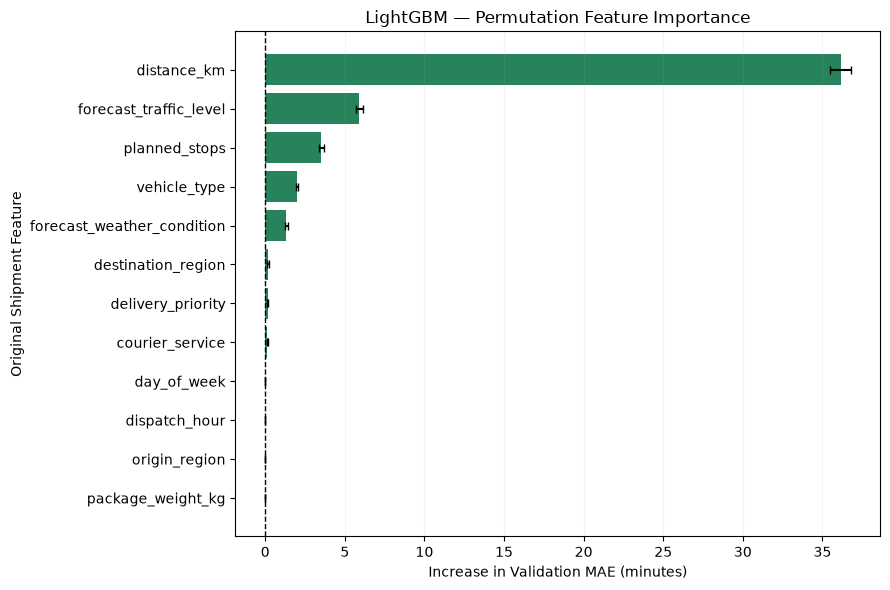

FEATURE IMPORTANCE TABLE AND FIGURE SAVED


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.inspection import permutation_importance
from IPython.display import display

# 1. Calculate permutation importance on validation data
importance_result = permutation_importance(
    estimator=lgbm_pipeline,
    X=X_val,
    y=y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# 2. Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "MAE_increase_min": importance_result.importances_mean,
    "Std_min": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "MAE_increase_min", ascending=False
).reset_index(drop=True)

print("=== LIGHTGBM PERMUTATION FEATURE IMPORTANCE ===")
print(f"Original validation MAE: {lgbm_val_mae:.2f} min")

display(importance_df.round(3))

# 3. Save the results
output_dir = DATA_PATH.parent.parent / "output"
figures_dir = output_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(
    output_dir / "feature_importance_validation.csv",
    index=False
)

# 4. Plot feature importance
plot_df = importance_df.sort_values(
    "MAE_increase_min", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    plot_df["Feature"],
    plot_df["MAE_increase_min"],
    xerr=plot_df["Std_min"],
    color="#27835b",
    capsize=3
)

ax.axvline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Increase in Validation MAE (minutes)")
ax.set_ylabel("Original Shipment Feature")
ax.set_title("LightGBM — Permutation Feature Importance")
ax.grid(axis="x", alpha=0.15)

fig.tight_layout()

fig.savefig(
    figures_dir / "06_feature_importance.png",
    dpi=150
)

plt.show()

print("FEATURE IMPORTANCE TABLE AND FIGURE SAVED")

## 17. Shipment ETA Predictions

Phase 4: create historical test predictions; future-shipment exports must exclude unknown actual outcomes.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [18]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# =====================================================
# 1. BUILD HISTORICAL SHIPMENT PREDICTION TABLE
# =====================================================

prediction_df = test_df[
    [
        "shipment_id",
        "dispatch_datetime",
        "destination_region",
        "distance_km",
        "promised_delivery_minutes"
    ]
].copy().reset_index(drop=True)

assert len(prediction_df) == len(final_test_pred) == len(y_test)

prediction_df["predicted_delivery_minutes"] = final_test_pred
prediction_df["actual_delivery_minutes"] = y_test.to_numpy()

# Positive error = actual duration exceeded prediction
prediction_df["prediction_error_minutes"] = (
    prediction_df["actual_delivery_minutes"]
    - prediction_df["predicted_delivery_minutes"]
)

# =====================================================
# 2. CALCULATE PREDICTED TIME BUFFER
# =====================================================

prediction_df["predicted_buffer_minutes"] = (
    prediction_df["promised_delivery_minutes"]
    - prediction_df["predicted_delivery_minutes"]
)

# =====================================================
# 3. DEFINE INITIAL OPERATIONAL RISK RULES
# =====================================================

monitor_buffer_minutes = 15.0

prediction_df["risk_category"] = np.select(
    [
        prediction_df["predicted_buffer_minutes"] <= 0,
        prediction_df["predicted_buffer_minutes"] <= monitor_buffer_minutes
    ],
    [
        "Potentially late",
        "Monitor closely"
    ],
    default="Lower concern"
)

# Flag TRUE only when predicted duration reaches
# or exceeds the promised duration.
prediction_df["estimated_delay_risk_flag"] = (
    prediction_df["risk_category"] == "Potentially late"
)

# =====================================================
# 4. ACTUAL LATE STATUS (HISTORICAL EVALUATION ONLY)
# =====================================================

prediction_df["actual_late_flag"] = (
    prediction_df["actual_delivery_minutes"]
    > prediction_df["promised_delivery_minutes"]
)

# Actual outcomes are NOT used to create risk categories.
# They are included only to evaluate historical performance.

# =====================================================
# 5. OVERALL OPERATIONAL KPIs
# =====================================================

total_shipments = len(prediction_df)

actual_late = int(
    prediction_df["actual_late_flag"].sum()
)

predicted_late = int(
    prediction_df["estimated_delay_risk_flag"].sum()
)

monitor_count = int(
    (prediction_df["risk_category"] == "Monitor closely").sum()
)

actual_late_rate = 100 * actual_late / total_shipments
predicted_late_rate = 100 * predicted_late / total_shipments

print("=== FINAL TEST OPERATIONAL OVERVIEW ===")
print(f"Total shipments: {total_shipments:,}")
print(f"Average actual duration: {prediction_df['actual_delivery_minutes'].mean():.2f} min")
print(f"Average predicted duration: {prediction_df['predicted_delivery_minutes'].mean():.2f} min")
print(f"Average promised duration: {prediction_df['promised_delivery_minutes'].mean():.2f} min")
print(f"Actual late shipments: {actual_late:,} ({actual_late_rate:.2f}%)")
print(f"Potentially late flags: {predicted_late:,} ({predicted_late_rate:.2f}%)")
print(f"Monitor closely: {monitor_count:,}")

# =====================================================
# 6. RISK CATEGORY PERFORMANCE
# =====================================================

risk_order = [
    "Potentially late",
    "Monitor closely",
    "Lower concern"
]

prediction_df["risk_category"] = pd.Categorical(
    prediction_df["risk_category"],
    categories=risk_order,
    ordered=True
)

risk_summary = prediction_df.groupby(
    "risk_category",
    observed=True
).agg(
    shipments=("shipment_id", "size"),
    actual_late_shipments=("actual_late_flag", "sum"),
    mean_predicted_minutes=("predicted_delivery_minutes", "mean"),
    mean_actual_minutes=("actual_delivery_minutes", "mean")
)

risk_summary["actual_late_rate_pct"] = (
    100
    * risk_summary["actual_late_shipments"]
    / risk_summary["shipments"]
)

print("\n=== RISK CATEGORY PERFORMANCE ===")
display(risk_summary.round(2))

# =====================================================
# 7. EVALUATE THE POTENTIALLY-LATE FLAG
# =====================================================

flagged = prediction_df["estimated_delay_risk_flag"]
late = prediction_df["actual_late_flag"]

true_positive = int((flagged & late).sum())
false_positive = int((flagged & ~late).sum())
false_negative = int((~flagged & late).sum())
true_negative = int((~flagged & ~late).sum())

flag_precision = (
    100 * true_positive / (true_positive + false_positive)
    if (true_positive + false_positive) > 0 else np.nan
)

flag_recall = (
    100 * true_positive / (true_positive + false_negative)
    if (true_positive + false_negative) > 0 else np.nan
)

print("\n=== POTENTIALLY-LATE FLAG ASSESSMENT ===")
print(f"Correctly flagged late: {true_positive:,}")
print(f"Flagged but actually on time: {false_positive:,}")
print(f"Late but not flagged: {false_negative:,}")
print(f"Correctly not flagged: {true_negative:,}")
print(f"Flag precision: {flag_precision:.2f}%")
print(f"Flag recall: {flag_recall:.2f}%")

assert (
    true_positive + false_positive
    + false_negative + true_negative
    == total_shipments
)

# =====================================================
# 8. SHOW EXAMPLE SHIPMENT PREDICTIONS
# =====================================================

print("\n=== SAMPLE SHIPMENT ETA PREDICTIONS ===")

display(
    prediction_df[
        [
            "shipment_id",
            "promised_delivery_minutes",
            "predicted_delivery_minutes",
            "predicted_buffer_minutes",
            "risk_category",
            "actual_delivery_minutes",
            "actual_late_flag"
        ]
    ].head(10).round(2)
)

# =====================================================
# 9. SAVE HISTORICAL SHIPMENT PREDICTIONS
# =====================================================

predictions_dir = (
    DATA_PATH.parent.parent / "output" / "predictions"
)

predictions_dir.mkdir(parents=True, exist_ok=True)

prediction_path = (
    predictions_dir / "shipment_eta_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

assert prediction_path.exists()
assert len(prediction_df) == 2000

print("\nSHIPMENT PREDICTIONS AND RISK FLAGS SAVED")
print(f"Saved file: {prediction_path.name}")

=== FINAL TEST OPERATIONAL OVERVIEW ===
Total shipments: 2,000
Average actual duration: 98.87 min
Average predicted duration: 98.58 min
Average promised duration: 116.01 min
Actual late shipments: 358 (17.90%)
Potentially late flags: 179 (8.95%)
Monitor closely: 627

=== RISK CATEGORY PERFORMANCE ===


,shipments,actual_late_shipments,mean_predicted_minutes,mean_actual_minutes,actual_late_rate_pct
risk_category,,,,,
Potentially late,179,117,141.32,142.82,65.36
Monitor closely,627,176,102.04,102.70,28.07
Lower concern,1194,65,90.36,90.27,5.44



=== POTENTIALLY-LATE FLAG ASSESSMENT ===
Correctly flagged late: 117
Flagged but actually on time: 62
Late but not flagged: 241
Correctly not flagged: 1,580
Flag precision: 65.36%
Flag recall: 32.68%

=== SAMPLE SHIPMENT ETA PREDICTIONS ===


,shipment_id,promised_delivery_minutes,predicted_delivery_minutes,predicted_buffer_minutes,risk_category,actual_delivery_minutes,actual_late_flag
0,SH-008315,120,109.76,10.24,Monitor closely,96.1,False
1,SH-007432,90,76.75,13.25,Monitor closely,71.6,False
2,SH-006147,160,118.48,41.52,Lower concern,101.0,False
3,SH-005718,85,40.02,44.98,Lower concern,39.3,False
4,SH-006065,105,87.33,17.67,Lower concern,85.7,False
5,SH-003505,165,161.29,3.71,Monitor closely,160.9,False
6,SH-004185,80,71.19,8.81,Monitor closely,60.6,False
7,SH-006938,105,74.73,30.27,Lower concern,88.9,False
8,SH-005930,85,82.17,2.83,Monitor closely,79.1,False
9,SH-002105,135,127.27,7.73,Monitor closely,143.6,True



SHIPMENT PREDICTIONS AND RISK FLAGS SAVED
Saved file: shipment_eta_predictions.csv


## 18. Late-Delivery Risk Analysis

Phase 4: compare predicted minutes with promised minutes, specify transparent review/monitor thresholds, and verify performance.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


In [ ]:
import json
import numpy as np
import pandas as pd
from IPython.display import display

# =====================================================
# 1. PREPARE OPERATIONAL INVESTIGATION DATA
# =====================================================

ops_df = prediction_df.copy()

ops_df["vehicle_type"] = test_df["vehicle_type"].to_numpy()
ops_df["forecast_traffic_level"] = (
    test_df["forecast_traffic_level"].to_numpy()
)
ops_df["delivery_priority"] = (
    test_df["delivery_priority"].to_numpy()
)

ops_df["distance_band"] = pd.cut(
    ops_df["distance_km"],
    bins=[0, 15, 30, 45, 60, np.inf],
    labels=["Under 15", "15 to <30", "30 to <45",
            "45 to <60", "60+"],
    right=False
)

ops_df["absolute_error_min"] = (
    ops_df["prediction_error_minutes"].abs()
)

ops_df["missed_late_flag"] = (
    ops_df["actual_late_flag"]
    & ~ops_df["estimated_delay_risk_flag"]
)

# =====================================================
# 2. SEGMENT-LEVEL LATE DELIVERY INVESTIGATION
# =====================================================

segment_columns = {
    "Distance band": "distance_band",
    "Destination region": "destination_region",
    "Vehicle type": "vehicle_type",
    "Traffic level": "forecast_traffic_level",
    "Delivery priority": "delivery_priority"
}

segment_results = []

for segment_name, column in segment_columns.items():

    summary = ops_df.groupby(
        column, observed=True
    ).agg(
        shipments=("shipment_id", "size"),
        actual_late=("actual_late_flag", "sum"),
        predicted_late_flags=("estimated_delay_risk_flag", "sum"),
        missed_late=("missed_late_flag", "sum"),
        mean_actual_min=("actual_delivery_minutes", "mean"),
        mean_error_min=("prediction_error_minutes", "mean"),
        mae_min=("absolute_error_min", "mean")
    )

    summary["late_rate_pct"] = (
        100 * summary["actual_late"] / summary["shipments"]
    )

    summary["missed_late_share_pct"] = (
        100 * summary["missed_late"]
        / max(int(ops_df["missed_late_flag"].sum()), 1)
    )

    summary = summary.sort_values(
        ["missed_late", "actual_late"],
        ascending=False
    )

    print(f"\n=== {segment_name.upper()} ===")
    display(summary.round(2))

    export_df = summary.reset_index().rename(
        columns={column: "segment_value"}
    )
    export_df.insert(0, "segment_type", segment_name)
    segment_results.append(export_df)

segment_summary_df = pd.concat(
    segment_results, ignore_index=True
)

# =====================================================
# 3. COMPARE TWO OPERATIONAL REVIEW POLICIES
# =====================================================

strict_review = (
    ops_df["risk_category"] == "Potentially late"
)

expanded_review = ops_df["risk_category"].isin([
    "Potentially late", "Monitor closely"
])

policy_results = []

for policy_name, review_mask in [
    ("Strict alert only", strict_review),
    ("Alert + monitor", expanded_review)
]:

    reviewed = int(review_mask.sum())

    late_caught = int(
        (review_mask & ops_df["actual_late_flag"]).sum()
    )

    ontime_reviewed = reviewed - late_caught

    actual_late_total = int(
        ops_df["actual_late_flag"].sum()
    )

    precision = (
        100 * late_caught / reviewed
        if reviewed else 0
    )

    recall = (
        100 * late_caught / actual_late_total
        if actual_late_total else 0
    )

    policy_results.append({
        "Policy": policy_name,
        "Reviewed": reviewed,
        "Actual_late_in_review": late_caught,
        "On_time_in_review": ontime_reviewed,
        "Review_load_pct": 100 * reviewed / len(ops_df),
        "Precision_pct": precision,
        "Recall_pct": recall
    })

policy_df = pd.DataFrame(policy_results)

print("\n=== OPERATIONAL REVIEW POLICY COMPARISON ===")
display(policy_df.round(2))

# =====================================================
# 4. HYPOTHETICAL BUSINESS EXPOSURE
# =====================================================

# Illustrative assumptions, NOT recorded company costs.
service_credit_inr = 150
review_cost_inr = 20

actual_late_total = int(
    ops_df["actual_late_flag"].sum()
)

scenario_df = policy_df[[
    "Policy", "Reviewed", "Actual_late_in_review"
]].copy()

scenario_df["Hypothetical_review_cost_INR"] = (
    scenario_df["Reviewed"] * review_cost_inr
)

scenario_df["Conditional_credit_exposure_INR"] = (
    scenario_df["Actual_late_in_review"]
    * service_credit_inr
)

total_conditional_credit = (
    actual_late_total * service_credit_inr
)

print("\n=== HYPOTHETICAL FINANCIAL SCENARIO ===")
print(f"Assumed service credit per eligible late shipment: Rs {service_credit_inr}")
print(f"Assumed operational review cost: Rs {review_cost_inr}")
print(f"Actual late shipments: {actual_late_total:,}")
print(f"Conditional credits if ALL late shipments qualify: Rs {total_conditional_credit:,}")

display(scenario_df)

print(
    "\nIMPORTANT: These are illustrative assumptions, "
    "not actual liabilities, verified costs or savings."
)

# =====================================================
# 5. SAVE OPERATIONAL ANALYSIS
# =====================================================

output_dir = DATA_PATH.parent.parent / "output"
output_dir.mkdir(parents=True, exist_ok=True)

segment_summary_df.to_csv(
    output_dir / "operational_segment_analysis.csv",
    index=False
)

policy_df.to_csv(
    output_dir / "risk_review_policy_comparison.csv",
    index=False
)

scenario_data = {
    "dataset_type": "synthetic",
    "test_shipments": int(len(ops_df)),
    "actual_late_shipments": actual_late_total,
    "service_credit_assumption_inr": service_credit_inr,
    "review_cost_assumption_inr": review_cost_inr,
    "conditional_total_credit_exposure_inr": total_conditional_credit,
    "policies": policy_df.to_dict(orient="records"),
    "note": (
        "Hypothetical scenario only. Historical late outcomes "
        "do not establish financial liability or intervention benefit."
    )
}

with open(
    output_dir / "operational_scenario.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(scenario_data, f, indent=4)

print("\nOPERATIONAL ANALYSIS AND SCENARIO FILES SAVED")

## 19. Business Recommendations

Phase 4: ranked findings, decision owners, transparent scenario impacts and measurable pilot success targets.

*Implementation will be completed in its planned phase; keep this section for transparent review.*


## 20. Limitations

Phase 4/5: simulation validity, forecast quality, drift, operational risk, no leakage and noncausal interpretation.

*Implementation will be completed in its planned phase; keep this section for transparent review.*
